## Sanity-check the new Largaespada data: is it reasonable to analyze with this pipeline?

A one-off check for this specific dataset, not a generic, reusable
notebook — runs before any saved model sees the new data, on purpose: a
formatting bug, a mismatched scale, or a biologically implausible sample
should be visible here, not discovered later as an implausible latent
score.

### Bottom line

**Yes, reasonable to run through this pipeline**, with one caveat. In order:
- **Scale and format**: 31 / 2,718 trained genes are entirely missing (imputed
  with the training mean, not dropped); the 1,203 genes flagged for an
  implausible value range are a sample-size artifact (8 new samples vs. 670
  training ones) — every one of them is narrower than train's range for that
  gene, never wider, which is what fewer draws should produce, not a unit
  mismatch. No evidence of a scale or formatting problem.
- **Position relative to training**: UMAP alone suggests the new samples sit
  apart from the training cohort, but UMAP is known to exaggerate separation
  between small groups — the more trustworthy check (nearest-neighbor
  distance through the actual saved PCA models) puts the median ratio at 1.03
  at 50 components (1.0 = exactly as isolated as an ordinary training sample
  already is from its neighbors). Not meaningfully more isolated than
  ordinary training variation.
- **Biological plausibility**: 2 / 8 new samples (`iPN3D`, `iPN2J`) show a
  statistically significant (p < 0.05) enrichment for resembling DepMap's own
  MPNST lines more than chance predicts, at 50 PCA components — notably the
  iPSC-derived lines, not the tumor-derived ones. The new sample named
  `S462` correlates with DepMap's own `S462` line at r=0.689 (71st
  percentile of all 1,150 DepMap lines) — elevated, consistent with real
  similarity, but not a standout identity confirmation on its own.

**The caveat**: this data sits at the edge of, not well inside, the training
cohort's dense region. Any resulting latent scores or pathway associations
should be read as extrapolation from a narrow biological niche DepMap's
broader cohort doesn't deeply cover, not as confident interpolation. The
rest of this notebook is the work behind those three bullets, in order of
cheap-and-definitive to expensive-and-suggestive.

Run this script with `8.apply-biobombe-new-data/` as the working directory.

In [1]:
import pathlib
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import umap
from scipy.spatial import cKDTree

sys.path.insert(0, "../utils")
from data_loader import load_train_test_data

In [2]:
train_test_data_directory = pathlib.Path("../1.data-exploration/data").resolve()
data_directory = pathlib.Path("../0.data-download/data").resolve()
model_save_dir = pathlib.Path("../3.run-biobombe/saved_models").resolve()
scaler_path = pathlib.Path("results/depmap_gene_scaler.joblib")
data_results_dir = pathlib.Path("data/largaespada/results")
data_results_dir.mkdir(parents=True, exist_ok=True)

In [3]:
new_scaled_df = pd.read_parquet(data_results_dir / "NF1_data_model_ready_scaled.parquet")
scaler_bundle = joblib.load(scaler_path)
gene_order = scaler_bundle["gene_order"]

# drop_columns=False keeps ModelID and every gene (unfiltered, unscaled);
# subsetting to gene_order here gives exactly what the scaler was fit on.
train_raw_df = load_train_test_data(train_test_data_directory, train_or_test="train", drop_columns=False)
train_raw_df = train_raw_df[["ModelID"] + gene_order]

train_scaled = scaler_bundle["scaler"].transform(train_raw_df[gene_order].values.astype(np.float32))
train_scaled_df = pd.DataFrame(train_scaled, columns=gene_order)
train_scaled_df.insert(0, "ModelID", train_raw_df["ModelID"].values)

# Restricted to the trained genes specifically (scaler_bundle["gene_order"]),
# not DepMap's full ~18,443-gene set: those are the only genes that actually
# reach model inference, and NF1_data_depmap_aligned.parquet's gene-symbol
# harmonization only ever targeted the trained set (see 0.preprocess_raw_data),
# so anything outside it was never checked for a correct alignment in the
# first place and would just be noise here. Read once here and reused by the
# name-matched correlation check in part 3 below.
new_raw_df = pd.read_parquet(data_results_dir / "NF1_data_depmap_aligned.parquet")
new_raw_values = new_raw_df[gene_order]
train_raw_values = train_raw_df[gene_order]

print(f"New data: {new_raw_df.shape[0]} samples, {len(gene_order)} trained genes")
print(f"Train data: {train_raw_df.shape[0]} samples")

New data: 8 samples, 2718 trained genes
Train data: 670 samples


## Part 1: per-gene sanity on the raw, pre-scaling values

In [4]:
new_stats = new_raw_values.stack().describe()
train_stats = train_raw_values.stack().describe()

comparison = pd.DataFrame({"new_data": new_stats, "train_data": train_stats})
print("Overall value distribution, new data vs. training data (raw, pre-scaling):")
comparison

Overall value distribution, new data vs. training data (raw, pre-scaling):


,new_data,train_data
count,21496.000000,1.821060e+06
mean,-0.586378,-6.039184e-01
std,0.614094,6.487947e-01
min,-3.816039,-5.465676e+00
25%,-0.901717,-9.547358e-01
50%,-0.421375,-4.063106e-01
75%,-0.155468,-1.227767e-01
max,1.850314,2.893550e+00


In [5]:
# Flag genes where the new data's value range looks implausible relative to
# the training data's, e.g. off by an order of magnitude, or a unit mismatch.
# With only 8 new samples against 670 training ones, expect most flags here
# to be a narrower new-data range (span_ratio well below 1) simply from
# having fewer draws, not a real problem — the conclusion below checks that
# this is actually what's happening rather than assuming it.
train_gene_range = train_raw_values.agg(["min", "max"]).T
new_gene_range = new_raw_values.agg(["min", "max"]).T

range_comparison = train_gene_range.join(new_gene_range, lsuffix="_train", rsuffix="_new", how="inner")
range_comparison["train_span"] = range_comparison["max_train"] - range_comparison["min_train"]
range_comparison["new_span"] = range_comparison["max_new"] - range_comparison["min_new"]
range_comparison["span_ratio"] = range_comparison["new_span"] / range_comparison["train_span"].replace(0, np.nan)

implausible_genes = range_comparison[
    (range_comparison["span_ratio"] > 3) | (range_comparison["span_ratio"] < (1 / 3))
].sort_values("span_ratio", ascending=False)

n_narrower = int((implausible_genes["span_ratio"] < 1).sum())
n_wider = int((implausible_genes["span_ratio"] > 1).sum())
print(f"{len(implausible_genes)} / {len(range_comparison)} trained genes have a value range "
      "more than 3x wider or narrower than the training data's for that gene.")
print(f"Of those, {n_narrower} are narrower (new data's range smaller than train's) vs. {n_wider} wider.")
implausible_genes.head(20)

1203 / 2718 trained genes have a value range more than 3x wider or narrower than the training data's for that gene.
Of those, 1203 are narrower (new data's range smaller than train's) vs. 0 wider.


,min_train,max_train,min_new,max_new,train_span,new_span,span_ratio
TRAPPC11 (60684),-2.175719,0.167293,-1.619210,-0.838221,2.343011,0.780989,0.333327
PSMD3 (5709),-4.343733,-0.919240,-1.909950,-0.768932,3.424493,1.141018,0.333193
SPI1 (6688),-1.853396,0.627664,-0.564954,0.261672,2.481060,0.826626,0.333175
VRK1 (7443),-2.267780,0.209600,-1.268675,-0.443389,2.477380,0.825286,0.333129
ATP6V1B2 (526),-3.206080,0.443350,-3.331565,-2.117617,3.649430,1.213948,0.332641
PKM (5315),-1.705666,0.112832,-1.294451,-0.689757,1.818498,0.604693,0.332523
COG3 (83548),-1.848349,0.075497,-1.312600,-0.673873,1.923846,0.638728,0.332006
FNDC10 (643988),-0.816578,0.392435,-0.353615,0.047684,1.209013,0.401299,0.331923
MTBP (27085),-2.707389,-0.623022,-1.794351,-1.102535,2.084367,0.691816,0.331907
SS18 (6760),-0.704020,0.681789,-0.230825,0.229133,1.385809,0.459957,0.331905


In [6]:
missingness = new_raw_values.isna().mean().sort_values(ascending=False)
n_fully_missing = int((missingness == 1.0).sum())
n_partially_missing = int((missingness > 0).sum())
print(f"Genes entirely missing from the new data: {n_fully_missing} / {len(missingness)}")
print(f"Genes with any missing values in the new data: {n_partially_missing} / {len(missingness)}")

sanity_summary = pd.DataFrame({
    "check": [
        "genes_fully_missing", "genes_partially_missing",
        "genes_with_implausible_range", "n_new_samples", "n_trained_genes",
    ],
    "value": [
        n_fully_missing, n_partially_missing,
        len(implausible_genes), new_raw_df.shape[0], range_comparison.shape[0],
    ],
})
sanity_summary.to_parquet(data_results_dir / "distribution_sanity_summary.parquet", index=False)
print(f"\nSaved sanity summary to {data_results_dir / 'distribution_sanity_summary.parquet'}")

Genes entirely missing from the new data: 31 / 2718
Genes with any missing values in the new data: 31 / 2718

Saved sanity summary to data/largaespada/results/distribution_sanity_summary.parquet


## Part 2: position relative to the training cohort

Two independent methods, because they don't agree equally well: UMAP is a
single low-dimensional embedding re-fit jointly on both groups every run,
which is known to exaggerate separation between small groups — informative
as a quick look, but not a trustworthy distance measurement on its own.
Projecting through the actual saved BioBombe PCA models (a fixed linear
map, fit only on the training data, not a fresh fit) at a few latent
dimensionalities gives a second, more quantitative read on the same
question that doesn't depend on what else happens to be in the plot.

### UMAP

In [7]:
combined = pd.concat(
    [train_scaled_df.assign(source="Train data"), new_scaled_df.assign(source="New data")],
    ignore_index=True,
)

reducer = umap.UMAP(random_state=0)
embedding = reducer.fit_transform(combined[gene_order].values)
combined["umap_1"] = embedding[:, 0]
combined["umap_2"] = embedding[:, 1]

/home/gway/miniconda3/envs/gene_dependency_representations/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


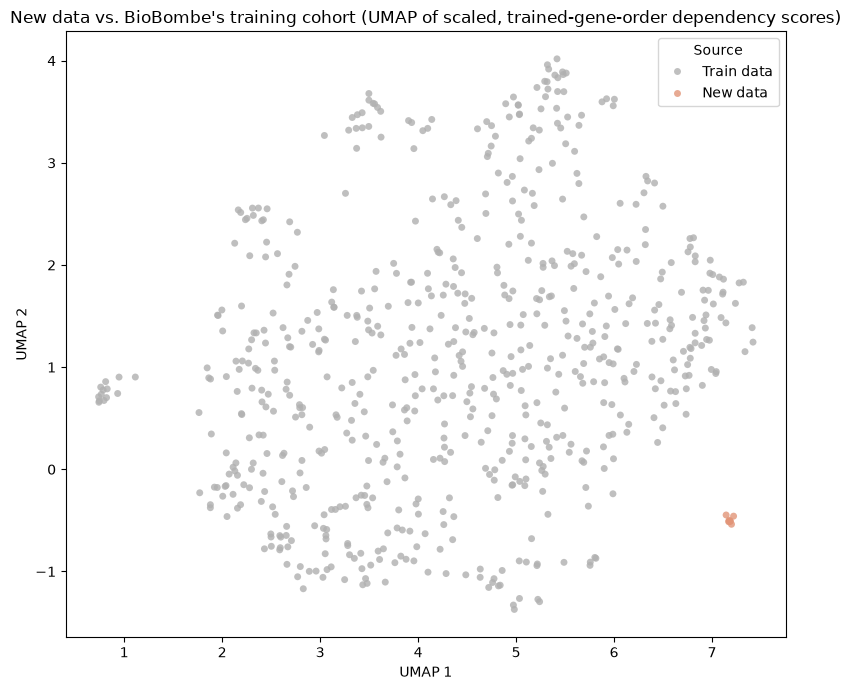

Saved UMAP coordinates (for the later R figure) to data/largaespada/results/NF1_data_umap_coordinates.parquet


In [8]:
# A quick look here, not the final figure — the publication-ready version of
# this plot gets built later in a dedicated R notebook, from the coordinates
# saved below, so this cell only displays inline and saves no image.
# "Train data" < "New data" alphabetically is the wrong draw order (matplotlib
# draws later rows on top, so sorting alphabetically draws Train data last,
# burying the new points) - draw_order fixes that explicitly instead.
draw_order = ["Train data", "New data"]
plt.figure(figsize=(8, 7))
sns.scatterplot(
    data=combined.assign(source=pd.Categorical(combined["source"], draw_order, ordered=True)).sort_values("source"),
    x="umap_1", y="umap_2", hue="source",
    palette={"Train data": "#B0B0B0", "New data": "#E29578"},
    s=25, alpha=0.8, edgecolor="none",
)
plt.title("New data vs. BioBombe's training cohort (UMAP of scaled, trained-gene-order dependency scores)")
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.legend(title="Source")
plt.tight_layout()
plt.show()

umap_coords_file = data_results_dir / "NF1_data_umap_coordinates.parquet"
combined[["ModelID", "source", "umap_1", "umap_2"]].to_parquet(umap_coords_file, index=False)
print(f"Saved UMAP coordinates (for the later R figure) to {umap_coords_file}")

### PCA: nearest-neighbor distance ratio, at several dimensionalities

For each new sample, its nearest-neighbor distance to the training cohort,
relative to how far training samples typically sit from each other. A
ratio near 1 means the new sample is no more isolated than an ordinary
training sample already is. Checked at a few latent dimensionalities (not
just 2), since a very low-dimensional projection discards most of the
original variance and can make a point look like more of an outlier than
it really is — exactly what happened with UMAP above, which made the new
data look far more isolated than the higher-dimensional PCA check agrees
with (see the conclusion for the actual numbers).

In [9]:
pca_dims_to_check = [2, 10, 50]
nn_ratio_rows = []
for dim in pca_dims_to_check:
    pca_model = joblib.load(model_save_dir / f"pca_latent_dims_{dim}_trial_non-optuna_init_0_seed_0.joblib")
    train_pcs = pca_model.transform(train_scaled_df[gene_order].values)
    new_pcs = pca_model.transform(new_scaled_df[gene_order].values)

    tree = cKDTree(train_pcs)
    new_dists, _ = tree.query(new_pcs, k=1)
    train_nn_dists, _ = tree.query(train_pcs, k=2)
    typical_train_nn = np.median(train_nn_dists[:, 1])

    for model_id, dist in zip(new_scaled_df["ModelID"], new_dists):
        nn_ratio_rows.append({
            "ModelID": model_id, "pca_latent_dim": dim,
            "distance_to_nearest_train_sample": dist,
            "typical_train_to_train_nn_distance": typical_train_nn,
            "ratio": dist / typical_train_nn,
        })

    if dim == 2:
        train_pcs_2d, new_pcs_2d = train_pcs, new_pcs

nn_ratio_df = pd.DataFrame(nn_ratio_rows)
print(nn_ratio_df.pivot(index="ModelID", columns="pca_latent_dim", values="ratio").round(2))

nn_ratio_file = data_results_dir / "NF1_data_pca_nn_ratios.parquet"
nn_ratio_df.to_parquet(nn_ratio_file, index=False)
print(f"\nSaved PCA nearest-neighbor ratios to {nn_ratio_file}")

pca_latent_dim    2     10    50
ModelID                         
S462            0.55  0.95  1.07
ST88-14         0.28  1.33  1.23
STS-26T         2.28  1.59  1.19
iHSC1L_C3       1.57  1.10  0.90
iHSC1L_F12      2.11  1.05  0.94
iPN1L           1.10  0.90  0.93
iPN2J           1.36  1.07  0.98
iPN3D           6.44  1.04  1.08

Saved PCA nearest-neighbor ratios to data/largaespada/results/NF1_data_pca_nn_ratios.parquet


## Part 3: biological plausibility specific to this dataset

DepMap lists 7 Malignant Peripheral Nerve Sheath Tumor (MPNST) lines
overall; `HS-Sch-2` is the only one actually in BioBombe's 670-model train
split (the other 6 either aren't in `CRISPRGeneEffect.csv` at all, or were
excluded from train/test/val for reasons unrelated to biological
relevance — three lines are missing `AgeCategory` metadata and were
dropped by `1.data-exploration`'s age-category filter entirely, two landed
in the held-out validation split by chance). Restricting to the train
split the way part 2 does would miss the most informative comparison
points available, so this part pulls all 5 DepMap MPNST lines with CRISPR
data straight from `CRISPRGeneEffect.csv` and scales them with the same
persisted scaler — a legitimate use of an already-fit scaler on new
points, same as for the new data itself, nothing here is refit.

In [10]:
model_metadata = pd.read_csv(data_directory / "Model.csv")
mpnst_ids = model_metadata.loc[
    model_metadata["OncotreeSubtype"] == "Malignant Peripheral Nerve Sheath Tumor", "ModelID"
]
mpnst_in_train = train_raw_df.loc[train_raw_df["ModelID"].isin(mpnst_ids), "ModelID"].tolist()
print(f"MPNST lines in DepMap overall: {len(mpnst_ids)}; in the train split: {mpnst_in_train}")

depmap_df = pd.read_csv(data_directory / "CRISPRGeneEffect.csv")
depmap_df = depmap_df.rename(columns={depmap_df.columns[0]: "ModelID"})
depmap_model_ids = depmap_df["ModelID"].values

depmap_values = depmap_df[gene_order].astype(float).fillna(scaler_bundle["gene_means"])
depmap_scaled = scaler_bundle["scaler"].transform(depmap_values.values.astype(np.float32))

known_mpnst_ids = {
    "ACH-002066": "HS-Sch-2", "ACH-002693": "S462 (DepMap)", "ACH-002710": "MPNST-724",
    "ACH-002799": "NCC-MPNST1-C1", "ACH-002800": "NCC-MPNST2-C1",
}
mpnst_labels = list(known_mpnst_ids.values())
mpnst_idx = np.array([np.where(depmap_model_ids == m)[0][0] for m in known_mpnst_ids])
non_mpnst_idx = np.array([i for i in range(len(depmap_model_ids)) if i not in set(mpnst_idx)])
# HS-Sch-2 is already shown via the train split in the 2D plot below; only
# the other four known MPNST lines need plotting as a separate group there.
other_mpnst_mask = np.array([k != "ACH-002066" for k in known_mpnst_ids])

# The 2D plot below needs a 2-component projection, even though the
# correlation test that follows skips latent_dim=2 (see below for why).
pca_model_2d = joblib.load(model_save_dir / "pca_latent_dims_2_trial_non-optuna_init_0_seed_0.joblib")
depmap_pcs_2d = pca_model_2d.transform(depmap_scaled)

MPNST lines in DepMap overall: 7; in the train split: ['ACH-002066']


### Are the new lines closer to DepMap's own MPNST lines than chance predicts?

A permutation test, run separately per new line rather than pooled across
all 8 (a pooled statistic can hide that some lines look MPNST-like while
others don't): each new sample's mean pairwise Pearson correlation, in PCA
space, with the 5 known MPNST lines, compared against the same statistic
for 10,000 random draws of 5 DepMap lines each. Pearson correlation
between two PCA coordinate vectors is degenerate at `latent_dim=2` (always
exactly ±1 with only 2 points to correlate over), so this uses 10/50/100
components instead of the 2/10/50 checked in part 2.

In [11]:
def vectorized_corr(X, y):
    """Pearson correlation between vector y and every row of matrix X."""
    X_c = X - X.mean(axis=1, keepdims=True)
    y_c = y - y.mean()
    return (X_c @ y_c) / (np.sqrt((X_c ** 2).sum(axis=1)) * np.sqrt((y_c ** 2).sum()))


pca_dims_for_correlation = [10, 50, 100]
rng = np.random.default_rng(0)
n_permutations = 10_000

proximity_rows = []
best_match_rows = []
null_dist_rows = []  # full null draws, dim=100 only, for the facet plot below
for dim in pca_dims_for_correlation:
    pca_model = joblib.load(model_save_dir / f"pca_latent_dims_{dim}_trial_non-optuna_init_0_seed_0.joblib")
    depmap_pcs = pca_model.transform(depmap_scaled)
    new_pcs = pca_model.transform(new_scaled_df[gene_order].values)
    mpnst_pcs = depmap_pcs[mpnst_idx]
    non_mpnst_pcs = depmap_pcs[non_mpnst_idx]

    for model_id, new_vec in zip(new_scaled_df["ModelID"], new_pcs):
        corr_to_mpnst = vectorized_corr(mpnst_pcs, new_vec)
        observed_stat = corr_to_mpnst.mean()

        # The null for "mean of a random 5" only needs each candidate's
        # correlation computed once; resampling means from that precomputed
        # array is what's repeated 10,000 times, not the correlation itself.
        corr_to_all_others = vectorized_corr(non_mpnst_pcs, new_vec)
        null_means = np.array([
            corr_to_all_others[rng.choice(len(corr_to_all_others), len(mpnst_idx), replace=False)].mean()
            for _ in range(n_permutations)
        ])
        p_value = (null_means >= observed_stat).mean()

        proximity_rows.append({
            "ModelID": model_id, "pca_latent_dim": dim,
            "observed_mean_correlation_to_mpnst_lines": observed_stat,
            "null_mean": null_means.mean(), "null_std": null_means.std(), "p_value": p_value,
        })

        if dim == 50:
            best = np.argmax(corr_to_mpnst)
            best_match_rows.append({
                "ModelID": model_id, "best_matching_mpnst_line": mpnst_labels[best],
                "correlation": corr_to_mpnst[best],
            })

        if dim == 100:
            null_dist_rows.append(pd.DataFrame({
                "ModelID": model_id, "null_mean_correlation": null_means,
                "observed_mean_correlation": observed_stat, "p_value": p_value,
            }))

proximity_df = pd.DataFrame(proximity_rows)
print(proximity_df.pivot(index="ModelID", columns="pca_latent_dim", values="p_value").round(4))

proximity_file = data_results_dir / "NF1_data_mpnst_proximity_test.parquet"
proximity_df.to_parquet(proximity_file, index=False)
print(f"\nSaved per-sample MPNST-proximity permutation test results to {proximity_file}")

pca_latent_dim     10      50      100
ModelID                               
S462            0.4886  0.5492  0.5824
ST88-14         0.4707  0.3234  0.3253
STS-26T         0.2443  0.0819  0.0641
iHSC1L_C3       0.4577  0.2492  0.2227
iHSC1L_F12      0.1808  0.0730  0.0589
iPN1L           0.1329  0.0604  0.0456
iPN2J           0.1771  0.0341  0.0296
iPN3D           0.0248  0.0016  0.0021

Saved per-sample MPNST-proximity permutation test results to data/largaespada/results/NF1_data_mpnst_proximity_test.parquet


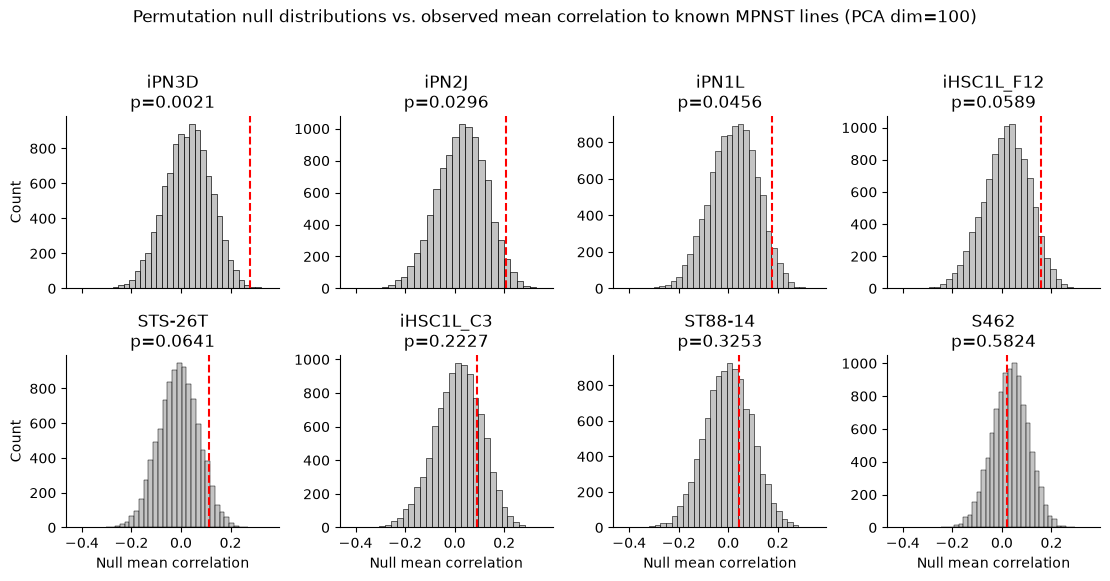

Saved dim=100 null distributions (for the later R figure) to data/largaespada/results/NF1_data_mpnst_proximity_null_distributions_dim100.parquet


In [12]:
# The full null distribution behind the dim=100 p-values above, one facet
# per new sample, so "closer than chance" is visible rather than taken on
# faith from a single number. Samples ordered by p-value (most to least
# significant) so the pattern across lines reads left-to-right.
null_dist_df = pd.concat(null_dist_rows, ignore_index=True)
sample_order = (
    null_dist_df[["ModelID", "p_value"]].drop_duplicates().sort_values("p_value")["ModelID"].tolist()
)

g = sns.FacetGrid(
    null_dist_df, col="ModelID", col_order=sample_order, col_wrap=4,
    sharex=True, sharey=False, height=2.8,
)
g.map(sns.histplot, "null_mean_correlation", bins=30, color="#B0B0B0")
for ax, model_id in zip(g.axes.flat, sample_order):
    row = null_dist_df.loc[null_dist_df["ModelID"] == model_id].iloc[0]
    ax.axvline(row["observed_mean_correlation"], color="red", linestyle="--", linewidth=1.5)
    ax.set_title(f"{model_id}\np={row['p_value']:.4f}")
g.set_axis_labels("Null mean correlation", "Count")
g.fig.suptitle(
    "Permutation null distributions vs. observed mean correlation to known MPNST lines (PCA dim=100)",
    y=1.03,
)
plt.tight_layout()
plt.show()

null_dist_file = data_results_dir / "NF1_data_mpnst_proximity_null_distributions_dim100.parquet"
null_dist_df.to_parquet(null_dist_file, index=False)
print(f"Saved dim=100 null distributions (for the later R figure) to {null_dist_file}")

In [13]:
# A specific, non-statistical check worth calling out on its own (at the
# dim=50 level): which single known MPNST line is each new sample most
# correlated with. The new sample actually named "S462" should, if
# anything, be most correlated with DepMap's own "S462" line specifically,
# not just the MPNST group in general, since they're plausibly the same
# underlying cell line screened independently by two different labs.
for row in best_match_rows:
    print(f"  {row['ModelID']}: best-matching known MPNST line = {row['best_matching_mpnst_line']} "
          f"(r={row['correlation']:.3f})")

  S462: best-matching known MPNST line = S462 (DepMap) (r=0.286)
  ST88-14: best-matching known MPNST line = S462 (DepMap) (r=0.328)
  STS-26T: best-matching known MPNST line = S462 (DepMap) (r=0.355)
  iHSC1L_C3: best-matching known MPNST line = S462 (DepMap) (r=0.337)
  iHSC1L_F12: best-matching known MPNST line = HS-Sch-2 (r=0.326)
  iPN1L: best-matching known MPNST line = HS-Sch-2 (r=0.401)
  iPN2J: best-matching known MPNST line = HS-Sch-2 (r=0.440)
  iPN3D: best-matching known MPNST line = HS-Sch-2 (r=0.593)


### Is a name-matched new sample actually that specific DepMap line?

The check above only compares each new sample against the 5 known MPNST
lines, so "best match" there means best *of those 5* — not necessarily a
strong match against DepMap as a whole. A sharper, independent question
for any new sample that shares a cell line name with an existing DepMap
model (matched via `Model.csv`'s `StrippedCellLineName`, case/punctuation
normalized): is the raw dependency profile actually correlated with that
specific DepMap line more than with DepMap broadly? This uses raw,
unscaled Pearson correlation across every gene both sides have a real
(non-missing) value for — not restricted to the trained gene set — since
this is a biological identity question, not a model-input one.

New samples matching a DepMap line by name: {'S462': 'ACH-002693'}



S462 vs. DepMap ACH-002693: r=0.689, rank 340 / 1150 (70.5th percentile), over 16850 / 18443 genes


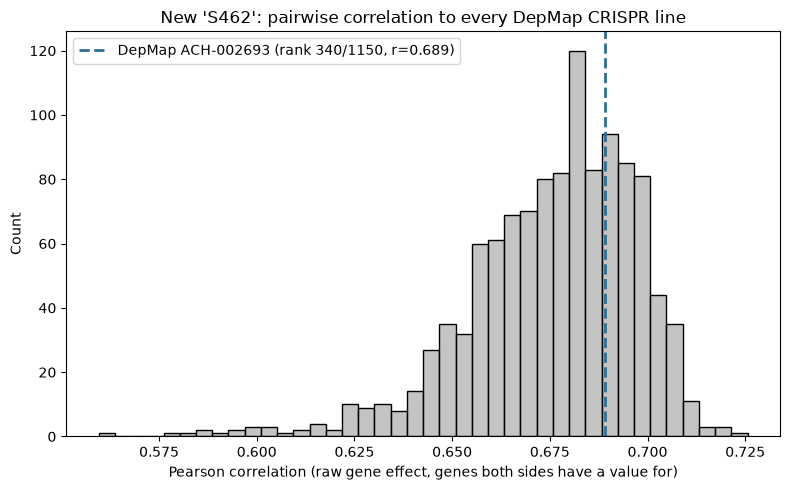


Saved name-matched correlation distributions to data/largaespada/results/NF1_data_name_matched_depmap_correlations.parquet


In [14]:
depmap_gene_columns = [c for c in depmap_df.columns if c != "ModelID"]

model_metadata["name_norm"] = model_metadata["StrippedCellLineName"].str.upper().str.replace(r"[^A-Z0-9]", "", regex=True)
new_name_norm = new_raw_df["ModelID"].str.upper().str.replace(r"[^A-Z0-9]", "", regex=True)
name_matches = dict(zip(
    new_raw_df["ModelID"][new_name_norm.isin(model_metadata["name_norm"])],
    model_metadata.set_index("name_norm").loc[new_name_norm[new_name_norm.isin(model_metadata["name_norm"])], "ModelID"],
))
print(f"New samples matching a DepMap line by name: {name_matches}")

depmap_indexed = depmap_df.set_index("ModelID")
correlation_rows = []
name_match_summary = {}
for new_id, matched_depmap_id in name_matches.items():
    new_profile = new_raw_df.loc[new_raw_df["ModelID"] == new_id, depmap_gene_columns].iloc[0]
    valid_genes = [g for g in new_profile.dropna().index if depmap_indexed[g].notna().all()]

    X = depmap_indexed[valid_genes].values.astype(float)
    y = new_profile[valid_genes].values.astype(float)
    X_c = X - X.mean(axis=1, keepdims=True)
    y_c = y - y.mean()
    correlations = pd.Series(
        (X_c @ y_c) / (np.sqrt((X_c ** 2).sum(axis=1)) * np.sqrt((y_c ** 2).sum())),
        index=depmap_indexed.index, name="pearson_correlation",
    )

    matched_corr = correlations.loc[matched_depmap_id]
    rank = int((correlations > matched_corr).sum()) + 1
    percentile = 100 * (1 - (rank - 1) / len(correlations))
    name_match_summary[new_id] = {
        "matched_depmap_id": matched_depmap_id, "r": matched_corr, "rank": rank,
        "n_candidates": len(correlations), "percentile": percentile,
    }
    print(f"\n{new_id} vs. DepMap {matched_depmap_id}: r={matched_corr:.3f}, "
          f"rank {rank} / {len(correlations)} ({percentile:.1f}th percentile), "
          f"over {len(valid_genes)} / {len(depmap_gene_columns)} genes")

    plt.figure(figsize=(8, 5))
    sns.histplot(correlations, bins=40, color="#B0B0B0")
    plt.axvline(
        matched_corr, color="#2a6f97", linestyle="--", linewidth=2,
        label=f"DepMap {matched_depmap_id} (rank {rank}/{len(correlations)}, r={matched_corr:.3f})",
    )
    plt.title(f"New '{new_id}': pairwise correlation to every DepMap CRISPR line")
    plt.xlabel("Pearson correlation (raw gene effect, genes both sides have a value for)")
    plt.ylabel("Count")
    plt.legend()
    plt.tight_layout()
    plt.show()

    correlation_rows.append(correlations.reset_index().assign(new_sample=new_id, matched_depmap_id=matched_depmap_id))

if correlation_rows:
    correlation_df = pd.concat(correlation_rows, ignore_index=True)
    correlation_file = data_results_dir / "NF1_data_name_matched_depmap_correlations.parquet"
    correlation_df.to_parquet(correlation_file, index=False)
    print(f"\nSaved name-matched correlation distributions to {correlation_file}")

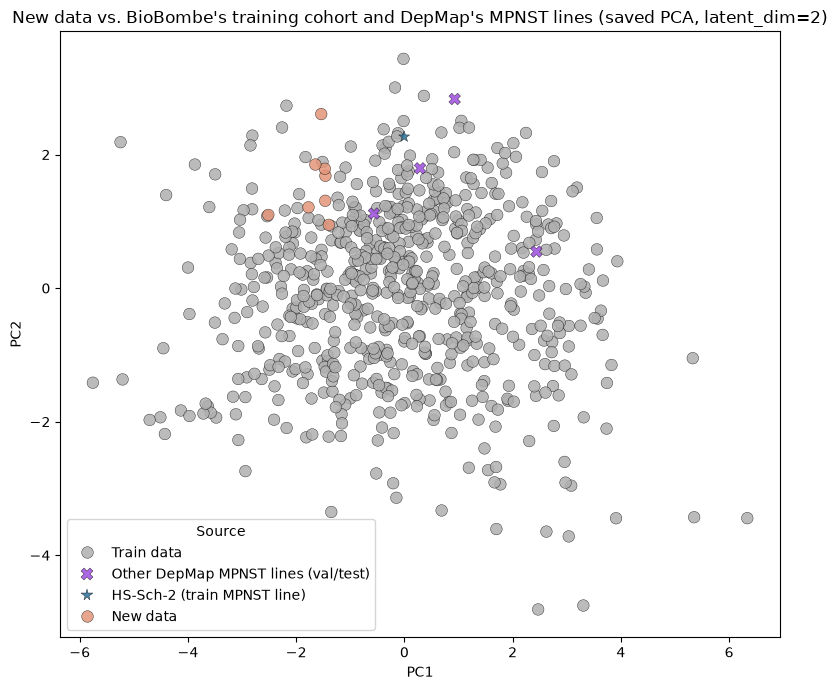

Saved PCA coordinates (for the later R figure) to data/largaespada/results/NF1_data_pca_coordinates.parquet


In [15]:
# The 2D case specifically, visualized — using the actual saved 2-latent-
# dimension PCA model, not a fresh fit, so a new sample's position is fixed
# regardless of what else is in the plot. Quick look only, same as the UMAP
# plot above: displays inline and saves coordinates (the full PCA-transformed
# data, not just this 2D view), not an image.
other_mpnst_df = pd.DataFrame({
    "ModelID": [k for k in known_mpnst_ids if k != "ACH-002066"],
    "pc1": depmap_pcs_2d[mpnst_idx[other_mpnst_mask], 0],
    "pc2": depmap_pcs_2d[mpnst_idx[other_mpnst_mask], 1],
    "source": "Other DepMap MPNST lines (val/test)",
})

pca_combined = pd.concat([
    train_raw_df[["ModelID"]].assign(pc1=train_pcs_2d[:, 0], pc2=train_pcs_2d[:, 1], source="Train data"),
    new_scaled_df[["ModelID"]].assign(pc1=new_pcs_2d[:, 0], pc2=new_pcs_2d[:, 1], source="New data"),
    other_mpnst_df,
], ignore_index=True)
pca_combined.loc[pca_combined["ModelID"].isin(mpnst_in_train), "source"] = "HS-Sch-2 (train MPNST line)"

# Train data first/bottom, New data last/on top — sorting by source name
# alphabetically would draw "Train data" last (on top), burying everything
# else under the grey background instead.
draw_order = ["Train data", "Other DepMap MPNST lines (val/test)", "HS-Sch-2 (train MPNST line)", "New data"]
plt.figure(figsize=(8, 7))
sns.scatterplot(
    data=pca_combined.assign(source=pd.Categorical(pca_combined["source"], draw_order, ordered=True)).sort_values("source"),
    x="pc1", y="pc2", hue="source",
    palette={
        "Train data": "#B0B0B0", "New data": "#E29578",
        "HS-Sch-2 (train MPNST line)": "#2a6f97", "Other DepMap MPNST lines (val/test)": "#9d4edd",
    },
    style="source",
    markers={
        "Train data": "o", "New data": "o",
        "HS-Sch-2 (train MPNST line)": "*", "Other DepMap MPNST lines (val/test)": "X",
    },
    s=70, alpha=0.85, edgecolor="black", linewidth=0.3,
)
plt.title("New data vs. BioBombe's training cohort and DepMap's MPNST lines (saved PCA, latent_dim=2)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Source")
plt.tight_layout()
plt.show()

pca_coords_file = data_results_dir / "NF1_data_pca_coordinates.parquet"
pca_combined.to_parquet(pca_coords_file, index=False)
print(f"Saved PCA coordinates (for the later R figure) to {pca_coords_file}")